<a href="https://colab.research.google.com/github/RubaSawalha4/joint-angle-trajectories/blob/main/joint_angle_trajectories(by_RubaS).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Joint-Angle Trajectories from Video: Falls vs Everyday Movement
**Ruba Sawalha · November 2026**

A single frame can be misleading: someone sitting down and someone starting to fall can look alike in one image. This notebook runs an open-source pose-estimation model (MediaPipe Pose) over short video sequences and analyses **hip, knee and trunk-angle trajectories over time**, to see how falls differ from everyday activities when movement is treated as a time series rather than a snapshot.

**Data:** UR Fall Detection Dataset (University of Rzeszów), 30 fall and 40 daily-activity sequences, front camera, 30 fps, 640×480, CC BY-NC-SA 4.0.
Kwolek & Kepski (2014), *Computer Methods and Programs in Biomedicine*, 117(3), 489–501.

#### 1. Data download

In [ ]:
#get the data
!mkdir -p data && cd data && \
wget -q https://fenix.ur.edu.pl/~mkepski/ds/data/adl-01-cam0-rgb.zip && \
wget -q https://fenix.ur.edu.pl/~mkepski/ds/data/adl-02-cam0-rgb.zip && \
wget -q https://fenix.ur.edu.pl/~mkepski/ds/data/fall-01-cam0-rgb.zip && \
for f in *.zip; do unzip -q -o "$f"; done
!ls -lh data
!ls data/adl-01-cam0-rgb | head -5
!ls data/adl-01-cam0-rgb | wc -l

total 201M
drwxr-xr-x 2 root root 12K Mar  3  2015 adl-01-cam0-rgb
-rw-r--r-- 1 root root 66M Feb 25  2020 adl-01-cam0-rgb.zip
drwxr-xr-x 2 root root 12K Mar  3  2015 adl-02-cam0-rgb
-rw-r--r-- 1 root root 80M Feb 25  2020 adl-02-cam0-rgb.zip
drwxr-xr-x 2 root root 12K Dec 11  2013 fall-01-cam0-rgb
-rw-r--r-- 1 root root 56M Feb 25  2020 fall-01-cam0-rgb.zip
adl-01-cam0-rgb-001.png
adl-01-cam0-rgb-002.png
adl-01-cam0-rgb-003.png
adl-01-cam0-rgb-004.png
adl-01-cam0-rgb-005.png
150


#### 2. Pose estimation on a single frame

In [ ]:
!pip install -q mediapipe
!wget -q -O pose_landmarker_full.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task
!ls -lh pose_landmarker_full.task

-rw-r--r-- 1 root root 9.0M Apr 28  2023 pose_landmarker_full.task


People detected: 1


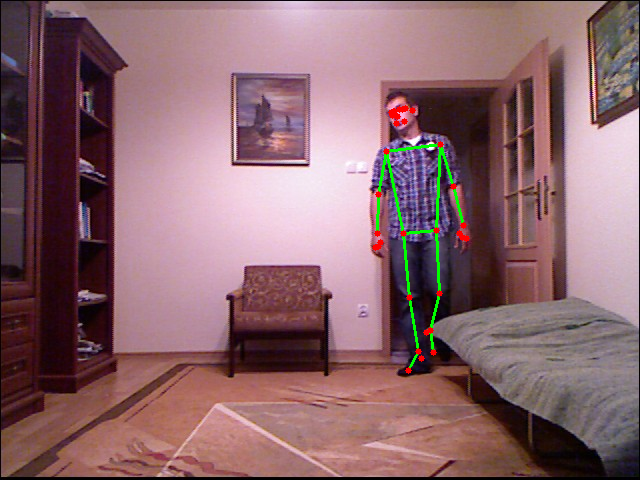

In [ ]:
import cv2, mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from google.colab.patches import cv2_imshow

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path='pose_landmarker_full.task'),
    running_mode=vision.RunningMode.IMAGE)
landmarker = vision.PoseLandmarker.create_from_options(options)

path = 'data/adl-01-cam0-rgb/adl-01-cam0-rgb-060.png'
result = landmarker.detect(mp.Image.create_from_file(path))
print('People detected:', len(result.pose_landmarks))

# draw the 33 landmarks and the main limb connections
CONNECTIONS = [(11,12),(11,13),(13,15),(12,14),(14,16),(11,23),(12,24),(23,24),
               (23,25),(25,27),(24,26),(26,28),(27,31),(28,32)]
img = cv2.imread(path); h, w = img.shape[:2]
if result.pose_landmarks:
    lm = result.pose_landmarks[0]
    pts = [(int(p.x*w), int(p.y*h)) for p in lm]
    for a, b in CONNECTIONS: cv2.line(img, pts[a], pts[b], (0,255,0), 2)
    for p in pts: cv2.circle(img, p, 3, (0,0,255), -1)
cv2_imshow(img)

#### 3. Pose estimation over the whole sequence

In [ ]:
import glob, numpy as np

def run_pose_on_sequence(folder, fps=30):
    frames = sorted(glob.glob(f'{folder}/*.png'))
    opts = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path='pose_landmarker_full.task'),
        running_mode=vision.RunningMode.VIDEO)
    lm_all = np.full((len(frames), 33, 3), np.nan)       # x, y, visibility
    with vision.PoseLandmarker.create_from_options(opts) as lmk:
        for i, f in enumerate(frames):
            res = lmk.detect_for_video(mp.Image.create_from_file(f), int(i * 1000 / fps))
            if res.pose_landmarks:
                lm_all[i] = [(p.x, p.y, p.visibility) for p in res.pose_landmarks[0]]
    return lm_all

seqs = {}
for name in ['adl-01', 'adl-02', 'fall-01']:
    seqs[name] = run_pose_on_sequence(f'data/{name}-cam0-rgb')
    detected = np.mean(~np.isnan(seqs[name][:, 0, 0])) * 100
    print(f'{name}: {seqs[name].shape}, person detected in {detected:.0f}% of frames')

adl-01: (150, 33, 3), person detected in 91% of frames
adl-02: (180, 33, 3), person detected in 77% of frames
fall-01: (160, 33, 3), person detected in 89% of frames


#### 4. Joint-angle trajectories

In [ ]:
from scipy.signal import savgol_filter
import pandas as pd

def angle(a, b, c):
    """Angle at point b (degrees) formed by a-b-c, per frame."""
    ba, bc = a - b, c - b
    cos = (ba * bc).sum(-1) / (np.linalg.norm(ba, axis=-1) * np.linalg.norm(bc, axis=-1))
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))

def joint_angles(lm, fps=30):
    xy = lm[:, :, :2]
    # average left and right side (indices: shoulder 11/12, hip 23/24, knee 25/26, ankle 27/28)
    sh, hip, knee, ank = [(xy[:, l] + xy[:, r]) / 2 for l, r in [(11,12), (23,24), (25,26), (27,28)]]
    knee_ang = angle(hip, knee, ank)                   # 180° = straight leg
    hip_ang  = angle(sh, hip, knee)                    # 180° = upright, smaller = bent at hip
    trunk = sh - hip                                   # vector hip -> shoulder
    trunk_lean = np.degrees(np.arctan2(np.abs(trunk[:, 0]), -trunk[:, 1]))  # 0° = vertical
    df = pd.DataFrame({'knee': knee_ang, 'hip': hip_ang, 'trunk_lean': trunk_lean})
    df = df.interpolate(limit_direction='both')        # fill frames with no detection
    df = df.apply(lambda s: savgol_filter(s, window_length=9, polyorder=2))  # smooth
    df['time_s'] = np.arange(len(df)) / fps
    return df

angles = {name: joint_angles(lm) for name, lm in seqs.items()}
angles['adl-01'].head()

,knee,hip,trunk_lean,time_s
0,172.893422,178.874161,1.3439,0.000000
1,172.893422,178.874161,1.3439,0.033333
2,172.893422,178.874161,1.3439,0.066667
3,172.893422,178.874161,1.3439,0.100000
4,172.893422,178.874161,1.3439,0.133333


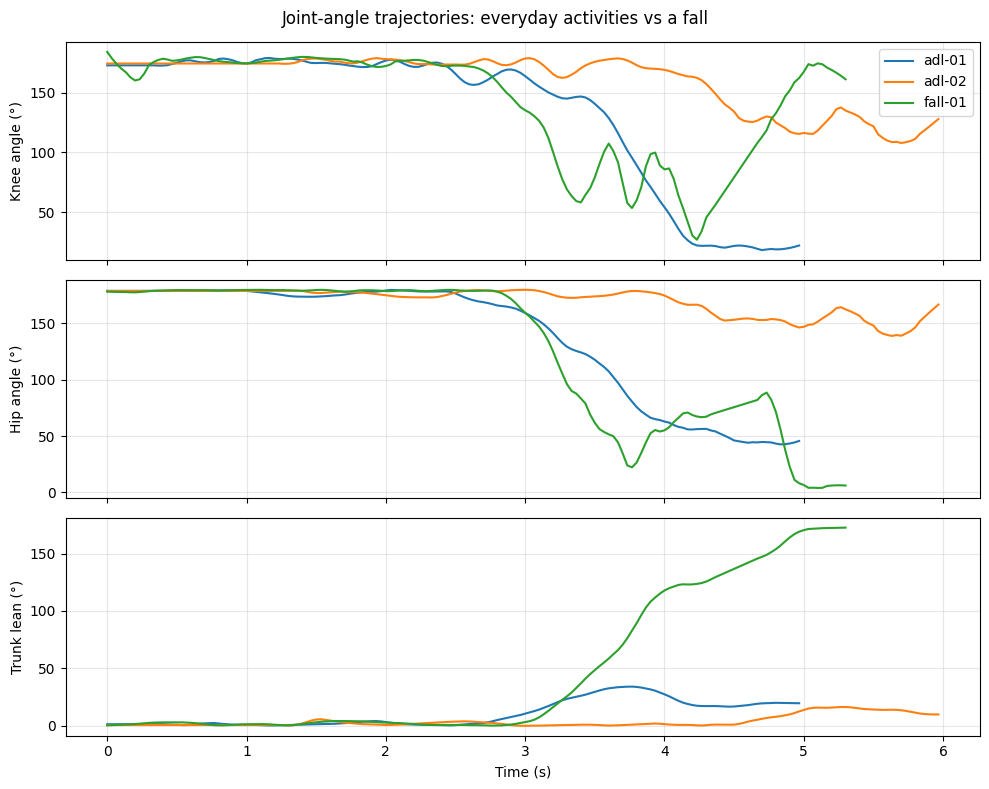

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for name, df in angles.items():
    for ax, col in zip(axes, ['knee', 'hip', 'trunk_lean']):
        ax.plot(df['time_s'], df[col], label=name)
for ax, col in zip(axes, ['Knee angle (°)', 'Hip angle (°)', 'Trunk lean (°)']):
    ax.set_ylabel(col); ax.grid(alpha=.3)
axes[0].legend(); axes[-1].set_xlabel('Time (s)')
plt.suptitle('Joint-angle trajectories: everyday activities vs a fall')
plt.tight_layout(); plt.show()

**First result.** In a single frame around t ≈ 3.5 s, the sitting-down activity (adl-01) and the fall (fall-01) show similar hip and knee angles. The trajectories, however, separate them clearly: during the fall the trunk lean rises from about 0° to 170° within roughly 1.5 s and then stays there (the person is lying on the floor), while in the everyday activities the trunk lean remains below about 30°. The knee and hip angles also fluctuate sharply during the fall, whereas in the activities of daily living they change smoothly and settle at a stable value.


#### 5. Scaling up: five everyday activities vs five falls

In [ ]:
import os
names = [f'adl-{i:02d}' for i in range(1, 6)] + [f'fall-{i:02d}' for i in range(1, 6)]

for name in names:
    if not os.path.isdir(f'data/{name}-cam0-rgb'):
        !cd data && wget -q https://fenix.ur.edu.pl/~mkepski/ds/data/{name}-cam0-rgb.zip && unzip -q -o {name}-cam0-rgb.zip
    if name not in seqs:
        seqs[name] = run_pose_on_sequence(f'data/{name}-cam0-rgb')
    angles[name] = joint_angles(seqs[name])
    print(name, 'done,', len(angles[name]), 'frames')

adl-01 done, 150 frames
adl-02 done, 180 frames
adl-03 done, 180 frames
adl-04 done, 150 frames
adl-05 done, 180 frames
fall-01 done, 160 frames
fall-02 done, 110 frames
fall-03 done, 215 frames
fall-04 done, 96 frames
fall-05 done, 151 frames


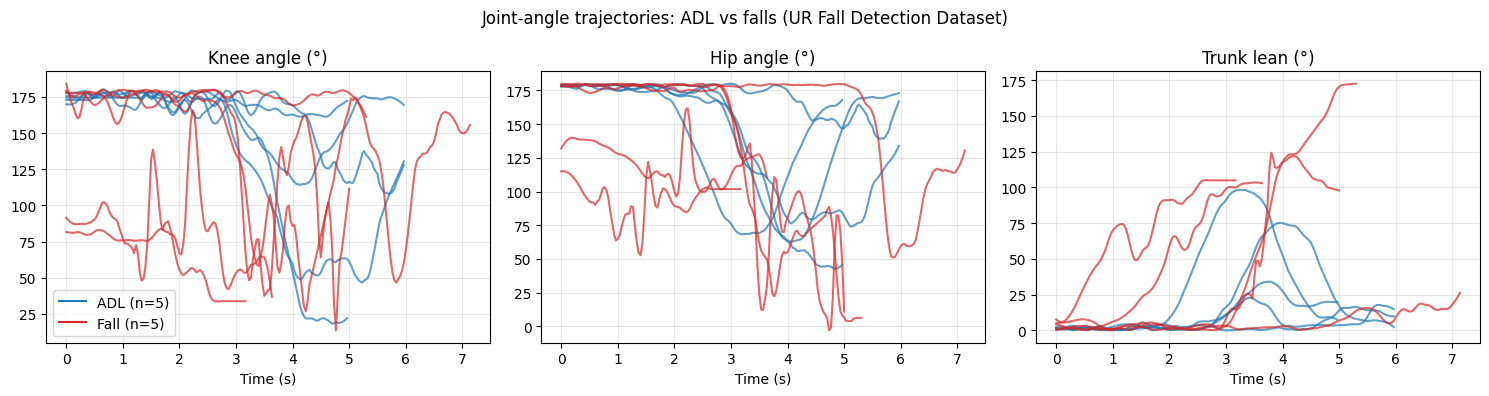

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in names:
    df, c = angles[name], ('tab:red' if name.startswith('fall') else 'tab:blue')
    for ax, col in zip(axes, ['knee', 'hip', 'trunk_lean']):
        ax.plot(df['time_s'], df[col], color=c, alpha=.7)
for ax, t in zip(axes, ['Knee angle (°)', 'Hip angle (°)', 'Trunk lean (°)']):
    ax.set_title(t); ax.set_xlabel('Time (s)'); ax.grid(alpha=.3)
axes[0].plot([], [], color='tab:blue', label='ADL (n=5)'); axes[0].plot([], [], color='tab:red', label='Fall (n=5)')
axes[0].legend()
plt.suptitle('Joint-angle trajectories: ADL vs falls (UR Fall Detection Dataset)')
plt.tight_layout(); plt.show()

#### 6. Trajectory features: speed, not just angle

,max_trunk_lean,peak_trunk_velocity,time_above_60deg_s,class
adl-01,34.1,58.4,0.0,ADL
adl-02,16.3,40.4,0.0,ADL
adl-03,22.9,69.8,0.0,ADL
adl-04,98.2,136.9,1.3,ADL
adl-05,75.1,110.7,1.0,ADL
fall-01,172.5,204.7,1.7,fall
fall-02,103.4,150.7,1.5,fall
fall-03,26.2,73.3,0.0,fall
fall-04,105.1,171.3,2.0,fall
fall-05,124.2,584.9,1.4,fall


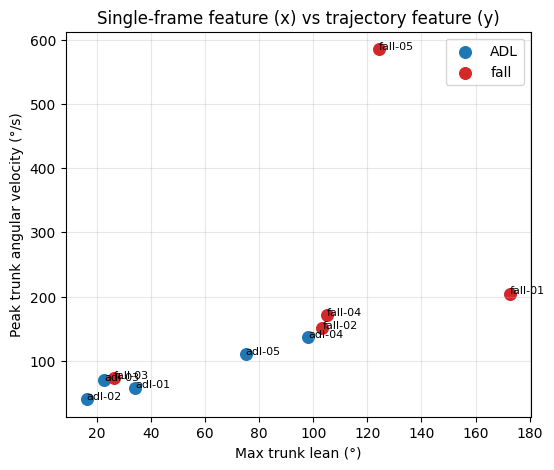

In [ ]:
def features(df, fps=30):
    tl = df['trunk_lean'].values
    vel = np.gradient(tl) * fps                      # deg/s
    return {'max_trunk_lean': tl.max(),
            'peak_trunk_velocity': np.abs(vel).max(),
            'time_above_60deg_s': (tl > 60).sum() / fps}

feat = pd.DataFrame({n: features(angles[n]) for n in names}).T
feat['class'] = ['fall' if n.startswith('fall') else 'ADL' for n in feat.index]
display(feat.round(1))

plt.figure(figsize=(6, 5))
for cls, c in [('ADL', 'tab:blue'), ('fall', 'tab:red')]:
    d = feat[feat['class'] == cls]
    plt.scatter(d['max_trunk_lean'], d['peak_trunk_velocity'], c=c, s=70, label=cls)
    for n, r in d.iterrows(): plt.annotate(n, (r['max_trunk_lean'], r['peak_trunk_velocity']), fontsize=8)
plt.xlabel('Max trunk lean (°)'); plt.ylabel('Peak trunk angular velocity (°/s)')
plt.title('Single-frame feature (x) vs trajectory feature (y)'); plt.grid(alpha=.3); plt.legend()
plt.show()

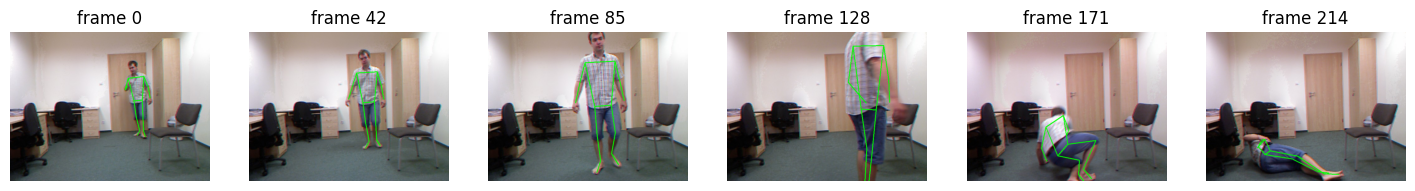

detected in 100.0 % of frames


In [ ]:
import matplotlib.image as mpimg
frames = sorted(glob.glob('data/fall-03-cam0-rgb/*.png'))
idx = np.linspace(0, len(frames) - 1, 6).astype(int)
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, i in zip(axes, idx):
    img = cv2.imread(frames[i]); h, w = img.shape[:2]
    lm = seqs['fall-03'][i]
    if not np.isnan(lm[0, 0]):
        pts = [(int(p[0]*w), int(p[1]*h)) for p in lm]
        for a, b in CONNECTIONS: cv2.line(img, pts[a], pts[b], (0,255,0), 2)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(f'frame {i}'); ax.axis('off')
plt.show()
print('detected in', np.mean(~np.isnan(seqs['fall-03'][:,0,0]))*100, '% of frames')

**Why fall-03 looks like a non-fall.** The subject walks towards the camera until the upper body leaves the frame, then falls backwards along the camera's optical axis. Because the trunk-lean angle is measured in the 2D image plane, motion along the viewing direction is foreshortened and the fall appears as a small tilt (max 26°). This illustrates a fundamental limitation of single-view 2D pose estimation: joint-angle trajectories are only reliable for movement roughly parallel to the image plane. Multi-view or 3D pose estimation, or depth sensing, would be needed to recover such events.

#### 8. Running directly on a video file

-rw-r--r-- 1 root root 1.2M Feb 25  2020 data/adl-01.mp4
frames: 150 fps: 30.0


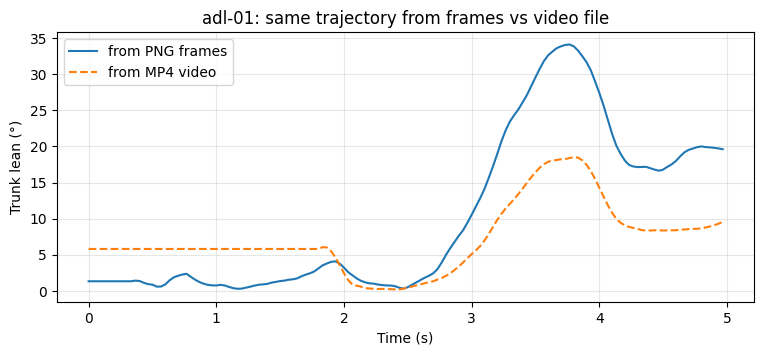

In [ ]:
URL = 'https://fenix.ur.edu.pl/~mkepski/ds/data/adl-01-cam0.mp4'
!wget -q -O data/adl-01.mp4 "$URL"
!ls -lh data/adl-01.mp4

def run_pose_on_video(path):
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    opts = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path='pose_landmarker_full.task'),
        running_mode=vision.RunningMode.VIDEO)
    rows = []
    with vision.PoseLandmarker.create_from_options(opts) as lmk:
        i = 0
        while True:
            ok, frame = cap.read()
            if not ok: break
            mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            res = lmk.detect_for_video(mp_img, int(i * 1000 / fps))
            rows.append([(p.x, p.y, p.visibility) for p in res.pose_landmarks[0]] if res.pose_landmarks else np.full((33, 3), np.nan))
            i += 1
    cap.release()
    return np.array(rows), fps

lm_video, fps = run_pose_on_video('data/adl-01.mp4')
print('frames:', len(lm_video), 'fps:', fps)
ang_video = joint_angles(lm_video, fps=fps)

plt.figure(figsize=(9, 3.5))
plt.plot(angles['adl-01']['time_s'], angles['adl-01']['trunk_lean'], label='from PNG frames')
plt.plot(ang_video['time_s'], ang_video['trunk_lean'], '--', label='from MP4 video')
plt.xlabel('Time (s)'); plt.ylabel('Trunk lean (°)'); plt.legend(); plt.grid(alpha=.3)
plt.title('adl-01: same trajectory from frames vs video file'); plt.show()

In [ ]:
det_png = np.mean(~np.isnan(seqs['adl-01'][:, 0, 0])) * 100
det_mp4 = np.mean(~np.isnan(lm_video[:, 0, 0])) * 100
r = np.corrcoef(angles['adl-01']['trunk_lean'], ang_video['trunk_lean'])[0, 1]
print(f'detection rate: PNG {det_png:.0f}%  vs  MP4 {det_mp4:.0f}%')
print(f'correlation of trunk-lean trajectories: r = {r:.2f}')
print(f'peak trunk lean: PNG {angles["adl-01"]["trunk_lean"].max():.1f}°  vs  MP4 {ang_video["trunk_lean"].max():.1f}°')

detection rate: PNG 91%  vs  MP4 61%
correlation of trunk-lean trajectories: r = 0.90
peak trunk lean: PNG 34.1°  vs  MP4 18.5°


**Frames vs compressed video.** Running the same model on the compressed MP4 (1.2 MB) instead of the PNG frames (66 MB) preserved the shape of the trunk-lean trajectory (r = 0.90) but reduced the detection rate from 91% to 61% of frames and halved the peak angle (18.5° vs 34.1°). Video compression therefore affects not only whether the person is detected but also the amplitude of the estimated joint angles, which matters for any system that will run on low-bitrate home cameras.

#### 9. Summary and limitations

**Summary.** An open-source pose-estimation model (MediaPipe Pose) was run over short video sequences from the UR Fall Detection Dataset (5 falls, 5 activities of daily living), and hip, knee and trunk-lean angles were analysed as trajectories over time. A single frame was often not enough to tell a fall from an everyday movement: hip and knee angles overlapped between sitting down and falling. The trajectories separated them better: in most falls the trunk lean rose above 100° within about one second, and peak trunk angular velocity was higher than in most activities. A fast "lying down" activity (adl-04) and a slower fall (fall-02) still overlapped, which shows that simple hand-crafted features are not enough on their own.

**Limitations.**
- **2D, single camera:** movement towards or away from the camera is foreshortened. In fall-03 the subject fell along the camera's viewing direction, and the trunk lean reached only 26°.
- **Detection gaps:** the person was missed in 9–23% of frames, mostly when partly out of view or lying down. These gaps were filled by interpolation.
- **Video quality:** on the compressed MP4, detection fell from 91% to 61%. The trajectory shape was kept (r = 0.90), but the peak angle was halved.
- **Small sample and no ground truth:** 10 sequences, young adults acting out falls, and no motion-capture reference for the angles.

**Next steps.** Validate the angles against motion capture, use 3D or multi-view pose, test on older adults' everyday movement, and learn temporal models (e.g. on joint-angle sequences) instead of thresholds.